# Assignment 9 - English-to-Hindi MT with Pretrained Embeddings

**Name:** Tanu Meena  
**Roll number:** U23AI076  
**Translation library:** OpenNMT-py 3.5.1

We compare two separately trained Transformers: pretrained FastText word
vectors and pretrained BPEmb subword vectors. The bitext and every split row
are reused from Lab 8. Its four source-length bins and SacreBLEU settings are
preserved. Lab 5 motivates vector initialization, Lab 3 motivates subwords,
and Labs 6-8 provide the saved-metrics and report structure.

Run cells in order. The supplied OpenNMT helper aligns vectors to the exact
vocabulary IDs, checks the saved tensors, and reports pretrained coverage.

In [1]:
import hashlib
import html
import io
import json
import math
import os
import re
import shutil
import subprocess
import sys
import tarfile
import time
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import yaml
from bpemb import BPEmb
from IPython.display import Markdown, display
from sacrebleu.metrics import BLEU

LAB_DIR = (Path(__file__).resolve().parent if '__file__' in globals() else
           Path.cwd() if (Path.cwd() / 'Assignment9_Pretrained_Embeddings_MT.py').exists()
           else Path.cwd() / 'Lab9')
ROOT = LAB_DIR.parent
OUT = LAB_DIR / 'assignment9_artifacts'
OUT.mkdir(parents=True, exist_ok=True)
SEED = 42
BINS = ['bin1', 'bin2', 'bin3', 'bin4']
TRAIN_STEPS = int(os.getenv('LAB9_TRAIN_STEPS', '8000'))
VALID_STEPS = math.gcd(1000, TRAIN_STEPS)
NOAM_FACTOR = 0.2
WORD_VOCAB = 12000
BP_VOCAB = 10000
EN_FASTTEXT_ROWS = int(os.getenv('LAB9_EN_FASTTEXT_ROWS', '250000'))
gpu_runtime = LAB_DIR / 'runtime' / 'python312' / 'python.exe'
local_runtime = gpu_runtime if gpu_runtime.exists() else ROOT / 'Lab8' / 'runtime' / 'python312' / 'python.exe'
ONMT_PYTHON = os.getenv('ONMT_PYTHON', str(local_runtime) if local_runtime.exists() else sys.executable)

def sha256(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()

def save_json(path, value):
    Path(path).write_text(json.dumps(value, indent=2, ensure_ascii=False), encoding='utf-8')

def run_command(command, log_path):
    environment = os.environ.copy()
    environment.update({'OMP_NUM_THREADS': os.getenv('LAB9_THREADS', '2'),
                        'MKL_NUM_THREADS': os.getenv('LAB9_THREADS', '2'),
                        'PYTHONIOENCODING': 'utf-8'})
    with Path(log_path).open('w', encoding='utf-8') as log:
        process = subprocess.Popen([str(x) for x in command], cwd=LAB_DIR,
            env=environment, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
            text=True, encoding='utf-8', errors='replace')
        for line in process.stdout:
            log.write(line)
            log.flush()
            if any(key in line for key in ['Step ', 'Validation perplexity', 'Saving checkpoint', 'ERROR']):
                print(line.strip(), flush=True)
        code = process.wait()
    if code:
        raise RuntimeError(f'Command failed ({code}).\n' + Path(log_path).read_text(encoding='utf-8')[-5000:])

probe = subprocess.run([ONMT_PYTHON, '-c',
    "import json,torch,onmt;print(json.dumps({'onmt':onmt.__version__,'torch':torch.__version__,'cuda':torch.cuda.is_available()}))"],
    capture_output=True, text=True, encoding='utf-8')
if probe.returncode:
    raise RuntimeError('Install OpenNMT requirements in Python 3.12.\n' + probe.stderr)
runtime = json.loads(probe.stdout.strip().splitlines()[-1])
assert runtime['onmt'] == '3.5.1'
print('OpenNMT:', runtime, 'training updates per variant:', TRAIN_STEPS)

OpenNMT: {'onmt': '3.5.1', 'torch': '2.2.2+cu121', 'cuda': True} training updates per variant: 8000


## 1. Reuse and verify the Lab 8 data

There are 128,605 training, 16,075 validation and 16,075 test pairs. We verify
all six plain-text split hashes against Lab 8's manifest. English whitespace
length before tokenization determines the bins: 1-10, 11-19, 20-29, and 30+.
Exactly 20 remains in bin 3, as documented in Lab 8.
Validation selects a checkpoint; test references are used only for evaluation.

In [2]:
prior = ROOT / 'Lab8' / 'assignment8_artifacts'
manifest = json.loads((prior / 'data_manifest.json').read_text(encoding='utf-8'))
splits = {}
for split in ['train', 'validation', 'test']:
    frame = pd.read_csv(prior / 'data' / f'{split}_pairs.csv', keep_default_na=False)
    splits[split] = frame
    assert len(frame) == manifest['split_sizes'][split]
    assert set(frame.bin) == set(BINS)
    for lang in ['en', 'hi']:
        path = prior / 'data' / f'{split}.{lang}'
        assert sha256(path) == manifest['split_sha256'][f'{split}.{lang}']
    assert (frame.source.str.split().str.len() == frame.source_length).all()
assert not set(splits['train'].source) & set(splits['test'].source)
assert not set(splits['train'].target) & set(splits['test'].target)
save_json(OUT / 'data_manifest.json', {'reused_from': str(prior), 'lab8_manifest': manifest})
shutil.copy2(prior / 'split_length_summary.csv', OUT / 'split_length_summary.csv')
display(pd.read_csv(OUT / 'split_length_summary.csv').round(2))

,split,bin,length_range,sentences,source_mean_words,source_min_words,source_max_words,target_mean_words
0,train,bin1,L <= 10,25856,7.56,1,10,9.17
1,train,bin2,11 <= L <= 19,53836,14.85,11,19,16.67
2,train,bin3,20 <= L <= 29,33320,23.72,20,29,25.61
3,train,bin4,L >= 30,15593,37.61,30,269,40.17
4,validation,bin1,L <= 10,3232,7.58,1,10,9.13
5,validation,bin2,11 <= L <= 19,6729,14.88,11,19,16.61
6,validation,bin3,20 <= L <= 29,4165,23.63,20,29,25.59
7,validation,bin4,L >= 30,1949,37.93,30,206,40.41
8,test,bin1,L <= 10,3232,7.58,1,10,9.19
9,test,bin2,11 <= L <= 19,6729,14.81,11,19,16.62


## 2. FastText word embeddings

The official pretrained Wiki `.vec` files have 300-dimensional word vectors.
We separate common punctuation from words, preserve case, and build source
and target vocabularies from training text only, capped at 12,000 words each.

To keep the English download manageable, we scan its first 250,000 vector
rows by default, retaining only training-vocabulary matches. We scan the full
smaller Hindi file. The exact URLs, limits, scanned-prefix hashes and coverage
are recorded. The English prefix is a resource limitation, not complete
FastText coverage. Set LAB9_EN_FASTTEXT_ROWS=0 to scan the full English file.

`.vec` files contain word vectors but no character n-gram model. Therefore
they cannot synthesize OOV embeddings as a FastText `.bin` model can.
Uncovered vocabulary entries and special tokens get seeded trainable random
vectors, while words outside the capped vocabulary map to `<unk>`.

In [3]:
def word_tokens(text):
    return re.sub(r'([.,!?;:()"“”])', r' \1 ', text).split()

def scan_fasttext(language, words):
    cache = OUT / 'fasttext_cache'
    cache.mkdir(exist_ok=True)
    path = cache / f'wiki.{language}.npz'
    marker = cache / f'wiki.{language}.json'
    limit = EN_FASTTEXT_ROWS if language == 'en' else 0
    url = f'https://dl.fbaipublicfiles.com/fasttext/vectors-wiki/wiki.{language}.vec'
    settings = {'url': url, 'row_limit': limit,
                'vocabulary_sha256': hashlib.sha256('\n'.join(sorted(words)).encode()).hexdigest()}
    old = json.loads(marker.read_text()) if marker.exists() else {}
    if path.exists() and old.get('settings') == settings and old.get('npz_sha256') == sha256(path):
        data = np.load(path)
        return dict(zip(data['tokens'].tolist(), data['vectors']))
    vectors = {}
    digest = hashlib.sha256()
    scanned = 0
    with requests.get(url, stream=True, timeout=(30, 180)) as response:
        response.raise_for_status()
        lines = response.iter_lines(chunk_size=1024*1024)
        header = next(lines)
        total, dimension = map(int, header.split())
        assert dimension == 300
        digest.update(header + b'\n')
        for line in lines:
            scanned += 1
            digest.update(line + b'\n')
            word_bytes, _, vector_bytes = line.partition(b' ')
            word = word_bytes.decode('utf-8', errors='strict')
            if word in words:
                vector = np.fromstring(vector_bytes.decode('ascii'), sep=' ', dtype='float32')
                if len(vector) == dimension and np.isfinite(vector).all():
                    vectors[word] = vector
            if scanned % 50000 == 0:
                print(language, 'FastText rows:', scanned, 'matched:', len(vectors), flush=True)
            if limit and scanned >= limit:
                break
    tokens = sorted(vectors)
    if len(tokens) < 128:
        raise ValueError('Insufficient pretrained matches for projection')
    np.savez_compressed(path, tokens=np.array(tokens), vectors=np.stack([vectors[t] for t in tokens]))
    save_json(marker, {'settings': settings, 'scanned_rows': scanned, 'total_rows': total,
                       'full_file_scanned': scanned == total, 'scanned_prefix_sha256': digest.hexdigest(),
                       'matched_types': len(tokens), 'npz_sha256': sha256(path)})
    return vectors

fasttext_vocab = {}
fasttext_vectors = {}
for language, column in [('en', 'source'), ('hi', 'target')]:
    counts = Counter(token for text in splits['train'][column] for token in word_tokens(text))
    vocabulary = [token for token, _ in counts.most_common(WORD_VOCAB)]
    fasttext_vocab[language] = vocabulary
    fasttext_vectors[language] = scan_fasttext(language, set(vocabulary))
    print(language, 'pretrained matched types:', len(fasttext_vectors[language]), flush=True)

en pretrained matched types: 8797
hi pretrained matched types: 10910


## 3. Encode text with BPEmb before using its embeddings

We use the official English and Hindi BPEmb models with 10,000 subwords and
300-dimensional pretrained vectors. BPEmb's SentencePiece model first encodes
each sentence, and its vector table supplies the embedding for each piece.
The pretrained segmenters are fixed and never fitted to test data.
We use BPEmb's standard lowercasing and digit-to-zero preprocessing, as
expected by its pretrained segmenters. Original references remain unchanged.

This computer has an old Gensim installation, so we use the actual BPEmb
library in segmentation-only mode and read its official word2vec binary
vector file directly with NumPy. This changes the file reader, not the
embeddings or segmentation. Every vector token is checked against the
corresponding SentencePiece ID. Archives are read by exact member name.

In [4]:
def read_word2vec_binary(path):
    result = {}
    with Path(path).open('rb') as handle:
        count, dimension = map(int, handle.readline().split())
        for _ in range(count):
            word = bytearray()
            while True:
                byte = handle.read(1)
                if not byte:
                    raise ValueError('Unexpected EOF in BPEmb vector file')
                if byte == b' ':
                    break
                if byte != b'\n' or word:
                    word.extend(byte)
            data = handle.read(4 * dimension)
            if len(data) != 4 * dimension:
                raise ValueError('Truncated BPEmb vector')
            result[word.decode('utf-8')] = np.frombuffer(data, dtype='<f4').copy()
    return result

bpemb_processors, bpemb_vectors = {}, {}
for language in ['en', 'hi']:
    cache = OUT / 'bpemb_cache' / language
    cache.mkdir(parents=True, exist_ok=True)
    model_name = f'{language}.wiki.bpe.vs{BP_VOCAB}.model'
    vector_name = f'{language}.wiki.bpe.vs{BP_VOCAB}.d300.w2v.bin'
    for name in [model_name, vector_name]:
        path = cache / name
        if path.exists():
            continue
        existing = Path.home() / '.cache' / 'bpemb' / language / name
        if existing.exists():
            shutil.copy2(existing, path)
            continue
        suffix = '.tar.gz' if name == vector_name else ''
        url = f'https://nlp.h-its.org/bpemb/{language}/{name}{suffix}'
        response = requests.get(url, timeout=(30, 180))
        response.raise_for_status()
        if suffix:
            with tarfile.open(fileobj=io.BytesIO(response.content), mode='r:gz') as archive:
                candidates = [member for member in archive.getmembers()
                              if member.isfile() and Path(member.name).name == name]
                if len(candidates) != 1:
                    raise ValueError('Unexpected BPEmb archive members')
                path.write_bytes(archive.extractfile(candidates[0]).read())
        else:
            path.write_bytes(response.content)
    processor = BPEmb(lang=language, vs=BP_VOCAB, dim=300, preprocess=True,
                      vs_fallback=False, segmentation_only=True, model_file=cache / model_name)
    vectors = read_word2vec_binary(cache / vector_name)
    assert processor.vs == BP_VOCAB and len(vectors) == BP_VOCAB
    assert all(processor.spm.id_to_piece(i) in vectors for i in range(BP_VOCAB))
    bpemb_processors[language] = processor
    bpemb_vectors[language] = vectors
    save_json(cache / 'manifest.json', {'model_sha256': sha256(cache / model_name),
               'vectors_sha256': sha256(cache / vector_name), 'vocabulary_size': BP_VOCAB,
               'dimension': 300, 'source': f'https://nlp.h-its.org/bpemb/{language}/',
               'extra_preprocessing': True})
    print(language, 'BPEmb example:', processor.encode(splits['train'].iloc[0][
          'source' if language == 'en' else 'target']), flush=True)

def encode_bpemb(language, text):
    processor = bpemb_processors[language]
    # SentencePiece string encoding may return the original unknown surface.
    # IDs give the canonical <unk> token expected by OpenNMT and BPEmb vectors.
    return [processor.spm.id_to_piece(index) for index in processor.encode_ids(text)]

for language, processor in bpemb_processors.items():
    ids = processor.encode_ids('x\u0378')
    pieces = encode_bpemb(language, 'x\u0378')
    assert 0 in ids and all(piece in bpemb_vectors[language] for piece in pieces)
    assert all(pieces[i] == '<unk>' for i, index in enumerate(ids) if index == 0)

en BPEmb example: ['▁on', '▁the', '▁power', '▁of', '▁her', '▁reputation', '▁,', '▁me', 'ena', '▁k', 'um', 'ari', '▁tried', '▁completely', '▁to', '▁take', '▁the', '▁career', '▁of', '▁d', 'har', 'm', 'end', 'ra', '▁to', '▁the', '▁heights', '▁.']
hi BPEmb example: ['▁अपनी', '▁शो', 'हर', 'त', '▁के', '▁बल', '▁पर', '▁मी', 'ना', '▁कु', 'मारी', '▁ने', '▁धर्', 'में', 'द्र', '▁के', '▁करियर', '▁को', '▁ऊंचाई', 'यों', '▁तक', '▁ले', '▁जाने', '▁की', '▁पूरी', '▁कोशिश', '▁की', '▁।']


## 4. Project embeddings and prepare both experiments

Both vector types start at dimension 300. To use the same small Transformer,
we fit a separate 300-to-128 PCA projection on covered training-vocabulary
types for each language/variant. We center vectors, project, and normalize
each row to norm `0.02*sqrt(128)`. This preserves projected vector direction
with a common scale; it does discard some pretrained information. Saved
projection matrices make this choice reproducible. Test data never fits PCA.

The tokenizations and vocabularies differ, so this is a comparison of two
embedding/tokenization pipelines rather than an embedding-only ablation.
Original Hindi references remain unchanged for SacreBLEU.

In [5]:
def projected_embeddings(vectors, training_tokens, path):
    covered = sorted(set(training_tokens) & vectors.keys())
    matrix = np.stack([vectors[token] for token in covered]).astype('float64')
    mean = matrix.mean(0)
    centered = matrix - mean
    # Eigenvectors of the small 300x300 covariance matrix are PCA directions.
    eigenvalues, eigenvectors = np.linalg.eigh(centered.T @ centered)
    order = np.argsort(eigenvalues)[::-1]
    components = eigenvectors[:, order[:128]]
    for column in range(128):
        pivot = np.argmax(np.abs(components[:, column]))
        if components[pivot, column] < 0:
            components[:, column] *= -1
    projected = centered @ components
    projected *= (0.02 * np.sqrt(128)) / np.maximum(np.linalg.norm(projected, axis=1, keepdims=True), 1e-12)
    np.savez_compressed(path, tokens=np.array(covered), vectors=projected.astype('float32'))
    np.savez_compressed(path.with_name(path.stem + '_pca.npz'), mean=mean, components=components)
    return {'covered_training_types': len(covered),
            'explained_variance_ratio': float(eigenvalues[order[:128]].sum() / eigenvalues.sum()),
            'projected_sha256': sha256(path)}

variants = {}
for variant in ['fasttext', 'bpemb']:
    directory = OUT / variant
    for sub in ['data', 'models']:
        (directory / sub).mkdir(parents=True, exist_ok=True)
    projections = {}
    for language, column in [('en', 'source'), ('hi', 'target')]:
        encode = word_tokens if variant == 'fasttext' else lambda text, lang=language: encode_bpemb(lang, text)
        for split, frame in splits.items():
            lines = [' '.join(encode(text)) for text in frame[column]]
            (directory / 'data' / f'{split}.{language}').write_bytes(('\n'.join(lines)+'\n').encode('utf-8'))
        counts = Counter((directory / 'data' / f'train.{language}').read_text(encoding='utf-8').split())
        vocabulary = [word for word, _ in counts.most_common(WORD_VOCAB)] if variant == 'fasttext' else list(counts)
        vectors = fasttext_vectors[language] if variant == 'fasttext' else bpemb_vectors[language]
        projections[language] = projected_embeddings(vectors, vocabulary,
                              directory / 'models' / f'projected_{language}.npz')
    config = {
        'data': {'corpus_1': {'path_src': str(directory / 'data/train.en'),
                             'path_tgt': str(directory / 'data/train.hi')},
                 'valid': {'path_src': str(directory / 'data/validation.en'),
                           'path_tgt': str(directory / 'data/validation.hi')}},
        'save_data': str(directory / 'data/onmt'),
        'src_vocab': str(directory / 'models/vocab.en.txt'),
        'tgt_vocab': str(directory / 'models/vocab.hi.txt'),
        'src_vocab_size': WORD_VOCAB+4 if variant == 'fasttext' else BP_VOCAB+4,
        'tgt_vocab_size': WORD_VOCAB+4 if variant == 'fasttext' else BP_VOCAB+4,
        'src_words_min_frequency': 1, 'tgt_words_min_frequency': 1,
        'share_vocab': False, 'overwrite': True, 'n_sample': 0,
        'save_model': str(directory / 'models/mt'), 'log_file': str(directory / 'onmt_training.log'),
        'encoder_type': 'transformer', 'decoder_type': 'transformer',
        'enc_layers': 2, 'dec_layers': 2, 'hidden_size': 128, 'word_vec_size': 128,
        'transformer_ff': 512, 'heads': 4, 'position_encoding': True,
        'dropout': [.1], 'attention_dropout': [.1], 'param_init': 0, 'param_init_glorot': True,
        'pre_word_vecs_enc': str(directory / 'models/pretrained.en.pt'),
        'pre_word_vecs_dec': str(directory / 'models/pretrained.hi.pt'),
        'freeze_word_vecs_enc': False, 'freeze_word_vecs_dec': False,
        'optim': 'adam', 'adam_beta1': .9, 'adam_beta2': .998,
        'learning_rate': NOAM_FACTOR, 'decay_method': 'noam', 'warmup_steps': 500,
        'max_grad_norm': 1., 'label_smoothing': .1, 'batch_type': 'tokens', 'batch_size': 1024,
        'valid_batch_size': 1024, 'bucket_size': 2048, 'num_workers': 0,
        'accum_count': [1], 'train_steps': TRAIN_STEPS, 'valid_steps': VALID_STEPS,
        'save_checkpoint_steps': VALID_STEPS, 'keep_checkpoint': -1,
        'early_stopping': 0, 'report_every': math.gcd(100, VALID_STEPS),
        'seed': SEED, 'world_size': 1}
    if runtime['cuda']:
        config['gpu_ranks'] = [0]
    config_path = directory / 'onmt_config.yaml'
    config_path.write_text(yaml.safe_dump(config, sort_keys=False), encoding='utf-8')
    fingerprint = hashlib.sha256(json.dumps({'config': config, 'data': manifest['split_sha256'],
                 'projections': projections, 'runtime': runtime}, sort_keys=True).encode()).hexdigest()
    variants[variant] = {'directory': directory, 'config_path': config_path,
                         'fingerprint': fingerprint, 'projections': projections}
save_json(OUT / 'projection_summary.json', {key: value['projections'] for key, value in variants.items()})
del fasttext_vectors, bpemb_vectors

## 5. Train the two OpenNMT Transformers

Both models use two encoder and two decoder layers, hidden size 128, four
heads, FFN size 512, dropout 0.1, Adam with Noam scheduling, label smoothing
0.1 and the same 8,000-update default budget. All embeddings are fine-tuned.
Noam's learning-rate factor is 0.2, with 500 warmup updates and gradient
clipping at norm 1. The effective peak rate is about 0.00079 for hidden
size 128. This gives the small model a more gradual optimization schedule.
Full Lab 8 splits are supplied, with no sentence-length filtering. A fixed
update budget does not guarantee every training sentence has been visited.
Tokenization changes batch composition, so equal updates are not equal words.

Before training, OpenNMT builds count vocabularies from training text. LF
line endings avoid the Windows vocabulary bug documented in Lab 8.
The helper uses OpenNMT's own vocabulary loader to align every tensor row.
Word vocabulary and pretrained coverage are audited; BPEmb should have full
training-token coverage. Lowest validation perplexity chooses a checkpoint.
Validation runs every 1,000 updates in the default experiment.
Perplexity uses different prediction units in the two vocabularies. It selects
checkpoints within each variant; BLEU compares the translation pipelines.

In [6]:
histories, selected_models, coverage_rows = {}, {}, []
for variant, experiment in variants.items():
    directory = experiment['directory']
    config_path = experiment['config_path']
    marker = directory / 'training_complete.json'
    previous = json.loads(marker.read_text()) if marker.exists() else {}
    reuse = (previous.get('fingerprint') == experiment['fingerprint'] and
             previous.get('checkpoints') and all((directory / 'models' / name).exists()
                                                 for name in previous['checkpoints']))
    if not reuse:
        started = time.perf_counter()
        run_command([ONMT_PYTHON, '-m', 'onmt.bin.build_vocab', '-config', config_path,
                     '-n_sample', '-1', '-num_threads', '1'], directory / 'build_vocab.log')
        for lang in ['en', 'hi']:
            path = directory / 'models' / f'vocab.{lang}.txt'
            path.write_bytes(('\n'.join(path.read_text(encoding='utf-8').splitlines())+'\n').encode('utf-8'))
        run_command([ONMT_PYTHON, LAB_DIR / 'prepare_onmt_embeddings.py', config_path],
                     directory / 'embedding_preparation.log')
        if variant == 'bpemb':
            coverage = json.loads((directory / 'embedding_coverage.json').read_text())
            assert all(value['training_token_vocabulary_coverage'] == 1. for value in coverage.values())
            assert all(value['training_token_pretrained_coverage'] == 1. for value in coverage.values())
        # Use a dedicated prefix per fingerprint to exclude stale checkpoints.
        checkpoints = list((directory / 'models').glob('mt_step_*.pt'))
        for path in checkpoints:
            path.unlink()
        print('Training', variant, flush=True)
        run_command([ONMT_PYTHON, '-m', 'onmt.bin.train', '-config', config_path], directory / 'train_console.log')
        checkpoints = sorted((directory / 'models').glob('mt_step_*.pt'))
        if not checkpoints:
            raise RuntimeError('No trained checkpoint was created')
        save_json(marker, {'fingerprint': experiment['fingerprint'],
                           'checkpoints': [path.name for path in checkpoints],
                           'training_seconds': time.perf_counter()-started})
    history, step = [], None
    for line in (directory / 'train_console.log').read_text(encoding='utf-8').splitlines():
        match = re.search(r'\bStep\s+(\d+)\s*/', line)
        if match:
            step = int(match.group(1))
        match = re.search(r'Validation perplexity:\s*([0-9.eE+-]+)', line)
        if match:
            history.append({'step': step, 'validation_perplexity': float(match.group(1))})
    history = pd.DataFrame(history)
    if history.empty:
        raise RuntimeError('No validation scores for model selection')
    history = history.loc[history.step.map(lambda step: (directory / 'models' / f'mt_step_{step}.pt').exists())]
    best = history.sort_values(['validation_perplexity', 'step']).iloc[0]
    selected = directory / 'models' / f'mt_step_{int(best.step)}.pt'
    histories[variant] = history
    selected_models[variant] = selected
    history.to_csv(directory / 'validation_history.csv', index=False)
    save_json(directory / 'selected_model.json', {'step': int(best.step),
        'validation_perplexity': float(best.validation_perplexity), 'sha256': sha256(selected),
        'selection': 'lowest validation perplexity; test not used'})
    for side, values in json.loads((directory / 'embedding_coverage.json').read_text()).items():
        coverage_rows.append({'variant': variant, 'side': side, **values})
coverage_table = pd.DataFrame(coverage_rows)
coverage_table.to_csv(OUT / 'embedding_coverage.csv', index=False)
display(coverage_table)

Training fasttext
[2026-11-07 18:54:17,872 INFO] Step 100/ 8000; acc: 4.6; ppl: 8411.9; xent: 9.0; lr: 0.00016; sents:    2861; bsz:  583/ 664/29; 12465/14217 tok/s;      5 sec;
[2026-11-07 18:54:22,033 INFO] Step 200/ 8000; acc: 6.9; ppl: 2037.8; xent: 7.6; lr: 0.00032; sents:    2950; bsz:  554/ 636/30; 13308/15280 tok/s;      9 sec;
[2026-11-07 18:54:26,139 INFO] Step 300/ 8000; acc: 9.5; ppl: 911.1; xent: 6.8; lr: 0.00048; sents:    2978; bsz:  592/ 672/30; 14427/16362 tok/s;     13 sec;
[2026-11-07 18:54:30,272 INFO] Step 400/ 8000; acc: 15.1; ppl: 641.9; xent: 6.5; lr: 0.00063; sents:    2877; bsz:  569/ 654/29; 13783/15822 tok/s;     17 sec;
[2026-11-07 18:54:34,338 INFO] Step 500/ 8000; acc: 18.9; ppl: 486.4; xent: 6.2; lr: 0.00079; sents:    2983; bsz:  592/ 670/30; 14565/16491 tok/s;     21 sec;
[2026-11-07 18:54:38,460 INFO] Step 600/ 8000; acc: 20.5; ppl: 405.2; xent: 6.0; lr: 0.00072; sents:    2922; bsz:  577/ 650/29; 13994/15771 tok/s;     25 sec;
[2026-11-07 18:54:42,69

,variant,side,vocab_size,pretrained_types,training_token_vocabulary_coverage,training_token_pretrained_coverage,training_unknown_token_rate,aligned_shape
0,fasttext,src,12008,8797,0.932937,0.832781,0.067063,"[12008, 128]"
1,fasttext,tgt,12008,10910,0.927449,0.896491,0.072551,"[12008, 128]"
2,bpemb,src,9624,9614,1.000000,1.000000,0.002447,"[9624, 128]"
3,bpemb,tgt,9544,9535,1.000000,1.000000,0.003867,"[9544, 128]"


## 6. Beam-search translation and detokenization

Beam size 5, Wu length penalty alpha=0.6, and a training-derived maximum
output length are fixed before test evaluation. Each decoder receives English
only. FastText output tokens are joined, while BPEmb pieces are decoded with
the matching Hindi SentencePiece model. All 16,075 test sentences are kept in
the original Lab 8 order, with original row IDs, bins and reference text.

In [7]:
prediction_frames = {}
for variant, experiment in variants.items():
    directory = experiment['directory']
    prediction_path = directory / 'test_predictions.tokens.hi'
    max_length = max(100, max(len(line.split()) for line in
                     (directory / 'data/train.hi').read_text(encoding='utf-8').splitlines())+10)
    settings = {'model_sha256': sha256(selected_models[variant]),
                'test_source_sha256': sha256(directory / 'data/test.en'),
                'beam_size': 5, 'max_length': max_length, 'alpha': .6}
    marker = directory / 'decode_manifest.json'
    previous = json.loads(marker.read_text()) if marker.exists() else {}
    if not (prediction_path.exists() and previous.get('settings') == settings and
            previous.get('prediction_sha256') == sha256(prediction_path)):
        run_command([ONMT_PYTHON, '-m', 'onmt.bin.translate', '-model', selected_models[variant],
                     '-src', directory / 'data/test.en', '-output', prediction_path,
                     '-gpu', '0' if runtime['cuda'] else '-1', '-beam_size', '5',
                     '-batch_size', '32', '-max_length', str(max_length),
                     '-length_penalty', 'wu', '-alpha', '.6', '-seed', str(SEED)], directory / 'translate.log')
    lines = prediction_path.read_text(encoding='utf-8').splitlines()
    assert len(lines) == len(splits['test'])
    hypotheses = [' '.join(line.split()) for line in lines] if variant == 'fasttext' else [
        bpemb_processors['hi'].spm.decode(line.split()) for line in lines]
    frame = splits['test'].copy()
    frame['prediction'] = hypotheses
    frame['prediction_words'] = [len(text.split()) for text in hypotheses]
    frame.to_csv(directory / 'test_predictions.csv', index=False)
    (directory / 'test_predictions.hi').write_text('\n'.join(hypotheses)+'\n', encoding='utf-8')
    prediction_frames[variant] = frame
    save_json(marker, {'settings': settings, 'prediction_sha256': sha256(prediction_path)})
    display(frame[['bin', 'source', 'target', 'prediction']].head())

,bin,source,target,prediction
0,bin2,Colourful birds capture the heart of tourists ...,रंग - बिरंगे पक्षी अपने मधुर गीत - संगीत से भ्...,<unk> <unk> के पर्यटकों को अपनी <unk> से <unk> ।
1,bin2,If you suspect your child may need special ser...,यदि आप शंकित हैं तो आपके बच्चे को मेमोरियल चिल...,यदि आप अपने बच्चे को <unk> <unk> के माध्यम से ...
2,bin2,"A wide array of wild orchids, ferns and wildfl...","जंगली आर्किड, फर्न्स और जंगलीफूलों की एक विस्त...","<unk> , <unk> , <unk> , <unk> , <unk> और <unk>..."
3,bin4,The celebrated Chinese traveler Huein Tsang vi...,प्रसिद्ध चीनी यात्री ह्युनसांग ने 7वीं शताब्दी...,<unk> राज्य के मध्य प्रदेश के मध्य प्रदेश के म...
4,bin1,A Frobenius norm how many of you get that now?,एक फ्रोबेनियस मानदंड है कि आप में से कितनो को ...,यह एक <unk> है कि आप वास्तव में क्या करते हैं ?


,bin,source,target,prediction
0,bin2,Colourful birds capture the heart of tourists ...,रंग - बिरंगे पक्षी अपने मधुर गीत - संगीत से भ्...,पक्षियों की खूबसूरती की खूबसूरती के चारों ओर आ...
1,bin2,If you suspect your child may need special ser...,यदि आप शंकित हैं तो आपके बच्चे को मेमोरियल चिल...,यदि आप अपने बच्चे कोविड-00 के माध्यम से उपलब्ध...
2,bin2,"A wide array of wild orchids, ferns and wildfl...","जंगली आर्किड, फर्न्स और जंगलीफूलों की एक विस्त...","वन्य जीवंतों के साथ, जंगली जानवरों के साथ-बड़ब..."
3,bin4,The celebrated Chinese traveler Huein Tsang vi...,प्रसिद्ध चीनी यात्री ह्युनसांग ने 7वीं शताब्दी...,00वीं शताब्दी के मध्य प्रदेश के मध्य प्रदेश के...
4,bin1,A Frobenius norm how many of you get that now?,एक फ्रोबेनियस मानदंड है कि आप में से कितनो को ...,एक ((|प्रोग्राम|function)) क्या है?


## 7. Overall and bin-wise SacreBLEU

Corpus BLEU is `100*BP*exp(mean(log(p1...p4)))`, using modified n-gram
precisions and a brevity penalty. We use exactly Lab 8's scoring convention:
case-sensitive, 13a tokenization, exponential smoothing, one reference, four
standard n-gram orders. Overall corpus BLEU is computed from all test rows,
not the average of the four bin scores. Signatures and length diagnostics
are saved. A single reference may penalize alternative valid translations.

In [8]:
score_rows = []
for variant, frame in prediction_frames.items():
    for name in BINS + ['overall']:
        group = frame if name == 'overall' else frame.loc[frame.bin == name]
        metric = BLEU(tokenize='13a', lowercase=False, smooth_method='exp', effective_order=False)
        score = metric.corpus_score(group.prediction.tolist(), [group.target.tolist()])
        score_rows.append({'variant': variant, 'bin': name, 'sentences': len(group),
                           'BLEU': score.score, 'brevity_penalty': score.bp,
                           'hypothesis_tokens': score.sys_len, 'reference_tokens': score.ref_len,
                           'length_ratio': score.sys_len / score.ref_len,
                           'signature': str(metric.get_signature())})
scores = pd.DataFrame(score_rows)
scores.to_csv(OUT / 'bin_wise_bleu.csv', index=False)
display(scores[['variant', 'bin', 'sentences', 'BLEU', 'brevity_penalty', 'length_ratio']].round(4))

That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


,variant,bin,sentences,BLEU,brevity_penalty,length_ratio
0,fasttext,bin1,3232,8.8565,1.0000,1.0888
1,fasttext,bin2,6729,7.0157,1.0000,1.1790
2,fasttext,bin3,4165,5.7543,1.0000,1.2607
3,fasttext,bin4,1949,5.3525,1.0000,1.3764
4,fasttext,overall,16075,6.2626,1.0000,1.2455
5,bpemb,bin1,3232,8.3931,0.8779,0.8848
6,bpemb,bin2,6729,6.4571,0.9105,0.9143
7,bpemb,bin3,4165,5.8678,0.8977,0.9026
8,bpemb,bin4,1949,5.9126,0.9413,0.9430
9,bpemb,overall,16075,6.2756,0.9110,0.9147


## 8. Measured comparison and bin-wise analysis

We compare scores with bin counts, output/reference length ratios and actual
translations. A score alone cannot establish why a variant wins. The short
training budget, capped word vocabulary, incomplete English FastText vector
scan, PCA projection and different segmenters are all part of this experiment.
Lab 8's separately trained BPE baseline used 5,000 updates, so it is reference
context rather than an equal-budget ablation.

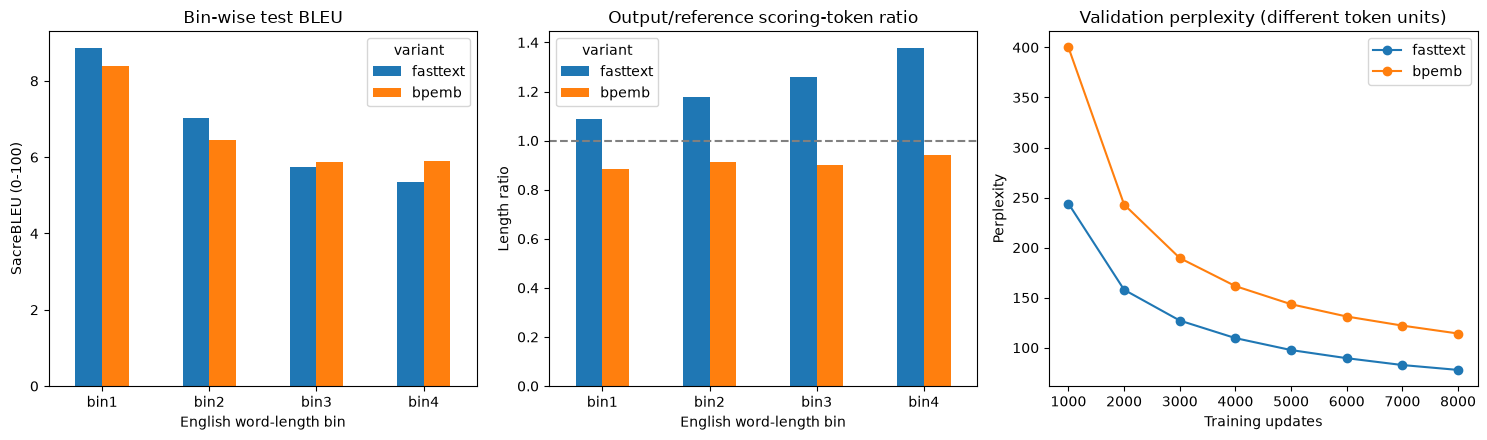

# Assignment 9 - Pretrained Embeddings for English-to-Hindi MT

Tanu Meena, U23AI076

The exact Lab 8 splits were reused and hash-verified: 128,605 training,
16,075 validation and 16,075 test pairs. Bins use original English word
length: 1-10, 11-19, 20-29 and 30+. Exactly 20 belongs to bin 3.

Both models: OpenNMT-py 3.5.1, 2 encoder/2 decoder Transformer layers,
hidden size 128, 4 heads, FFN 512, 8000 updates, label smoothing 0.1,
Adam with Noam schedule, dropout 0.1; pretrained embeddings fine-tuned.
Noam factor 0.2, 500 warmup updates, gradient norm clipping at 1.
Validation runs every 1000 updates. Effective peak learning rate is about 0.00079.
Validation perplexity selects the checkpoint; beam size 5 translates test.

FastText uses official 300D Wiki word vectors and a capped 12,000-word
vocabulary per language. English scan limit: 250000 rows (0 means full).
Hindi vectors were fully scanned. Uncovered rows use seeded random vectors.
BPEmb uses official English/Hindi 10,000-piece segmenters and 300D vectors.
Text is encoded with BPEmb before vector lookup. Training-type PCA reduces
both variants to 128D, followed by equal row scaling. PCA is saved.

## Actual test results

| Embeddings | Bin | Test pairs | BLEU | Brevity penalty | Length ratio |
| --- | --- | ---: | ---: | ---: | ---: |
| fasttext | bin1 | 3232 | 8.8565 | 1.0000 | 1.0888 |
| fasttext | bin2 | 6729 | 7.0157 | 1.0000 | 1.1790 |
| fasttext | bin3 | 4165 | 5.7543 | 1.0000 | 1.2607 |
| fasttext | bin4 | 1949 | 5.3525 | 1.0000 | 1.3764 |
| fasttext | overall | 16075 | 6.2626 | 1.0000 | 1.2455 |
| bpemb | bin1 | 3232 | 8.3931 | 0.8779 | 0.8848 |
| bpemb | bin2 | 6729 | 6.4571 | 0.9105 | 0.9143 |
| bpemb | bin3 | 4165 | 5.8678 | 0.8977 | 0.9026 |
| bpemb | bin4 | 1949 | 5.9126 | 0.9413 | 0.9430 |
| bpemb | overall | 16075 | 6.2756 | 0.9110 | 0.9147 |

## Bin-wise observations

bin1: BPEmb-minus-FastText BLEU is -0.4634. FastText length ratio is 1.0888; BPEmb length ratio is 0.8848. Ratios below one indicate shorter output than the reference and may help explain the brevity penalty, but do not alone identify an error source.

bin2: BPEmb-minus-FastText BLEU is -0.5585. FastText length ratio is 1.1790; BPEmb length ratio is 0.9143. Ratios below one indicate shorter output than the reference and may help explain the brevity penalty, but do not alone identify an error source.

bin3: BPEmb-minus-FastText BLEU is +0.1135. FastText length ratio is 1.2607; BPEmb length ratio is 0.9026. Ratios below one indicate shorter output than the reference and may help explain the brevity penalty, but do not alone identify an error source.

bin4: BPEmb-minus-FastText BLEU is +0.5601. FastText length ratio is 1.3764; BPEmb length ratio is 0.9430. Ratios below one indicate shorter output than the reference and may help explain the brevity penalty, but do not alone identify an error source.

fasttext: strongest bin is bin1 (8.8565); weakest is bin4 (5.3525).

bpemb: strongest bin is bin1 (8.3931); weakest is bin3 (5.8678).

## Coverage and limitations

| variant   | side   |   vocab_size |   pretrained_types |   training_token_vocabulary_coverage |   training_token_pretrained_coverage |   training_unknown_token_rate | aligned_shape   |
|:----------|:-------|-------------:|-------------------:|-------------------------------------:|-------------------------------------:|------------------------------:|:----------------|
| fasttext  | src    |        12008 |               8797 |                             0.932937 |                             0.832781 |                    0.067063   | [12008, 128]    |
| fasttext  | tgt    |        12008 |              10910 |                             0.927449 |                             0.896491 |                    0.0725512  | [12008, 128]    |
| bpemb     | src    |         9624 |               9614 |                             1        |                             1        |                    0.00244745 | [9624, 128]     |
| bpemb     | tgt    |         9544 |               9535 |                             1        |                             1        |                    0.00386722 | [9544, 128]     |

Scores measure these two complete pipelines. Tokenization, vocabulary size,
PCA loss and partial English vector coverage confound an embedding-only claim.
BPEmb additionally lowercases inputs and replaces digits with zero; FastText
preserves them. BPEmb encoding uses canonical IDs so unknown surface forms
map to `<unk>` consistently. Original Hindi references are never normalized.
Pretrained coverage includes the supplied BPEmb `<unk>` vector; the separately
reported unknown-token rate measures tokens whose surface information is lost.
The fixed update budget may not traverse all training rows. Low scores describe
a small educational baseline, not a deployable translation system. Lab 8 used
5,000 updates and is not an equal-budget comparator. Test was not used for
checkpoint selection. Overall BLEU is a separate corpus calculation.

Perplexity uses different word/subword prediction units, so it selects checkpoints
within each variant. BLEU provides the comparison across the translators.

## Actual translation examples

### fasttext, bin1

English: A Frobenius norm how many of you get that now?

Hindi reference: एक फ्रोबेनियस मानदंड है कि आप में से कितनो को अब वह मिलता है?

Prediction: यह एक &lt;unk&gt; है कि आप वास्तव में क्या करते हैं ?

### fasttext, bin2

English: Colourful birds capture the heart of tourists by their sweet songs .

Hindi reference: रंग - बिरंगे पक्षी अपने मधुर गीत - संगीत से भ्रमणकारियों का मन मोह लेते हैं ।

Prediction: &lt;unk&gt; &lt;unk&gt; के पर्यटकों को अपनी &lt;unk&gt; से &lt;unk&gt; ।

### fasttext, bin3

English: National Institution of Nutrition , Hyderabad has researched that the seeds of fenugreek are panacea for the diabetes patients .

Hindi reference: नेशनल इंस्टीट्‍यूट ऑफ न्यूटीशन हैदराबाद के वैज्ञानिकों का शोध है कि मेंथी के दाने मधुमेह के रोगियों के लिए रामबाण हैं

Prediction: &lt;unk&gt; राष्‍ट्रीय उद्यान के &lt;unk&gt; ने बताया है कि इन रोगियों के लिए इन रोगियों के लिए &lt;unk&gt; हैं ।

### fasttext, bin4

English: The celebrated Chinese traveler Huein Tsang visited the state in the middle of 7th century A.D. Nearly half (44%) of the state is forested and offers a unique panorama of flora and fauna.

Hindi reference: प्रसिद्ध चीनी यात्री ह्युनसांग ने 7वीं शताब्दी ई. के मध्य राज्य की यात्रा की।

Prediction: &lt;unk&gt; राज्य के मध्य प्रदेश के मध्य प्रदेश के मध्य में मनाया जाता है . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . .

### bpemb, bin1

English: A Frobenius norm how many of you get that now?

Hindi reference: एक फ्रोबेनियस मानदंड है कि आप में से कितनो को अब वह मिलता है?

Prediction: एक ((|प्रोग्राम|function)) क्या है?

### bpemb, bin2

English: Colourful birds capture the heart of tourists by their sweet songs .

Hindi reference: रंग - बिरंगे पक्षी अपने मधुर गीत - संगीत से भ्रमणकारियों का मन मोह लेते हैं ।

Prediction: पक्षियों की खूबसूरती की खूबसूरती के चारों ओर आते हैं ।

### bpemb, bin3

English: National Institution of Nutrition , Hyderabad has researched that the seeds of fenugreek are panacea for the diabetes patients .

Hindi reference: नेशनल इंस्टीट्‍यूट ऑफ न्यूटीशन हैदराबाद के वैज्ञानिकों का शोध है कि मेंथी के दाने मधुमेह के रोगियों के लिए रामबाण हैं

Prediction: राष् ⁇ ट्रीय पोषक तत्वों की रोकथाम की जाती है , जो मधुमेह के लिए , मधुमेह के रोगियों के लिए किया जाता है ।

### bpemb, bin4

English: The celebrated Chinese traveler Huein Tsang visited the state in the middle of 7th century A.D. Nearly half (44%) of the state is forested and offers a unique panorama of flora and fauna.

Hindi reference: प्रसिद्ध चीनी यात्री ह्युनसांग ने 7वीं शताब्दी ई. के मध्य राज्य की यात्रा की।

Prediction: 00वीं शताब्दी के मध्य प्रदेश के मध्य प्रदेश के बीच, 00वीं शताब्दी के मध्य प्रदेश के मध्य प्रदेश के लगभग 00 किलोमीटर दूर है।

## References

- Previous solution: ../Lab8/Assignment8_English_Hindi_MT.ipynb
- FastText vectors: https://fasttext.cc/docs/en/pretrained-vectors.html
- BPEmb: https://github.com/bheinzerling/bpemb
- OpenNMT-py: https://github.com/OpenNMT/OpenNMT-py
- SacreBLEU: https://github.com/mjpost/sacrebleu

Scoring signature: nrefs:1|case:mixed|eff:no|tok:13a|smooth:exp|version:2.6.0


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
palette = {'fasttext': '#1f77b4', 'bpemb': '#ff7f0e'}
scores.loc[scores.bin != 'overall'].pivot(index='bin', columns='variant', values='BLEU').reindex(BINS)[list(palette)].plot.bar(ax=axes[0], rot=0, color=palette)
axes[0].set(title='Bin-wise test BLEU', ylabel='SacreBLEU (0-100)', xlabel='English word-length bin')
scores.loc[scores.bin != 'overall'].pivot(index='bin', columns='variant', values='length_ratio').reindex(BINS)[list(palette)].plot.bar(ax=axes[1], rot=0, color=palette)
axes[1].axhline(1, color='grey', linestyle='--')
axes[1].set(title='Output/reference scoring-token ratio', ylabel='Length ratio', xlabel='English word-length bin')
for variant, history in histories.items():
    axes[2].plot(history.step, history.validation_perplexity, marker='o', label=variant, color=palette[variant])
axes[2].set(title='Validation perplexity (different token units)', xlabel='Training updates', ylabel='Perplexity')
axes[2].legend()
fig.tight_layout()
fig.savefig(OUT / 'embedding_mt_comparison.png', dpi=180)
display(fig)
plt.close(fig)
table = ['| Embeddings | Bin | Test pairs | BLEU | Brevity penalty | Length ratio |',
         '| --- | --- | ---: | ---: | ---: | ---: |']
for row in scores.itertuples(index=False):
    table.append(f'| {row.variant} | {row.bin} | {row.sentences} | {row.BLEU:.4f} | {row.brevity_penalty:.4f} | {row.length_ratio:.4f} |')
lines = ['# Assignment 9 - Pretrained Embeddings for English-to-Hindi MT', '',
         'Tanu Meena, U23AI076', '',
         'The exact Lab 8 splits were reused and hash-verified: 128,605 training,',
         '16,075 validation and 16,075 test pairs. Bins use original English word',
         'length: 1-10, 11-19, 20-29 and 30+. Exactly 20 belongs to bin 3.', '',
         f'Both models: OpenNMT-py 3.5.1, 2 encoder/2 decoder Transformer layers,',
         f'hidden size 128, 4 heads, FFN 512, {TRAIN_STEPS} updates, label smoothing 0.1,',
         'Adam with Noam schedule, dropout 0.1; pretrained embeddings fine-tuned.',
         f'Noam factor {NOAM_FACTOR}, 500 warmup updates, gradient norm clipping at 1.',
         f'Validation runs every {VALID_STEPS} updates. Effective peak learning rate is about 0.00079.',
         'Validation perplexity selects the checkpoint; beam size 5 translates test.', '',
         'FastText uses official 300D Wiki word vectors and a capped 12,000-word',
         f'vocabulary per language. English scan limit: {EN_FASTTEXT_ROWS} rows (0 means full).',
         'Hindi vectors were fully scanned. Uncovered rows use seeded random vectors.',
         'BPEmb uses official English/Hindi 10,000-piece segmenters and 300D vectors.',
         'Text is encoded with BPEmb before vector lookup. Training-type PCA reduces',
         'both variants to 128D, followed by equal row scaling. PCA is saved.', '',
         '## Actual test results', '', *table, '', '## Bin-wise observations', '']
for name in BINS:
    group = scores.loc[scores.bin == name].set_index('variant')
    delta = group.loc['bpemb', 'BLEU']-group.loc['fasttext', 'BLEU']
    lines.append(f'{name}: BPEmb-minus-FastText BLEU is {delta:+.4f}. '
                 f'FastText length ratio is {group.loc["fasttext", "length_ratio"]:.4f}; '
                 f'BPEmb length ratio is {group.loc["bpemb", "length_ratio"]:.4f}. '
                 'Ratios below one indicate shorter output than the reference and may '
                 'help explain the brevity penalty, but do not alone identify an error source.')
    lines.append('')
for variant in variants:
    group = scores.loc[(scores.variant == variant) & (scores.bin != 'overall')]
    best = group.loc[group.BLEU.idxmax()]
    worst = group.loc[group.BLEU.idxmin()]
    lines.append(f'{variant}: strongest bin is {best.bin} ({best.BLEU:.4f}); '
                 f'weakest is {worst.bin} ({worst.BLEU:.4f}).')
    lines.append('')
lines.extend(['## Coverage and limitations', '', coverage_table.to_markdown(index=False), '',
              'Scores measure these two complete pipelines. Tokenization, vocabulary size,',
              'PCA loss and partial English vector coverage confound an embedding-only claim.',
              'BPEmb additionally lowercases inputs and replaces digits with zero; FastText',
              'preserves them. BPEmb encoding uses canonical IDs so unknown surface forms',
              'map to `<unk>` consistently. Original Hindi references are never normalized.',
              'Pretrained coverage includes the supplied BPEmb `<unk>` vector; the separately',
              'reported unknown-token rate measures tokens whose surface information is lost.',
              'The fixed update budget may not traverse all training rows. Low scores describe',
              'a small educational baseline, not a deployable translation system. Lab 8 used',
              '5,000 updates and is not an equal-budget comparator. Test was not used for',
              'checkpoint selection. Overall BLEU is a separate corpus calculation.', '',
              'Perplexity uses different word/subword prediction units, so it selects checkpoints',
              'within each variant. BLEU provides the comparison across the translators.', '',
              '## Actual translation examples', ''])
for variant, frame in prediction_frames.items():
    for name in BINS:
        example = frame.loc[frame.bin == name].iloc[0]
        lines.extend([f'### {variant}, {name}', '', f'English: {html.escape(example.source)}', '',
                      f'Hindi reference: {html.escape(example.target)}', '', f'Prediction: {html.escape(example.prediction)}', ''])
lines.extend(['## References', '',
              '- Previous solution: ../Lab8/Assignment8_English_Hindi_MT.ipynb',
              '- FastText vectors: https://fasttext.cc/docs/en/pretrained-vectors.html',
              '- BPEmb: https://github.com/bheinzerling/bpemb',
              '- OpenNMT-py: https://github.com/OpenNMT/OpenNMT-py',
              '- SacreBLEU: https://github.com/mjpost/sacrebleu', '',
              'Scoring signature: ' + scores.signature.iloc[0]])
report = '\n'.join(lines)+'\n'
(OUT / 'assignment9_report.md').write_text(report, encoding='utf-8')
save_json(OUT / 'completed_run.json', {'variants': list(variants), 'train_steps': TRAIN_STEPS,
           'test_sentences': len(splits['test']), 'scores_sha256': sha256(OUT / 'bin_wise_bleu.csv')})
display(Markdown(report))